# Transfer Learning con MobileNetV3Small
Notebook preparado para clasificación binaria de imágenes de **220×220×3**.

Flujo:
1. Cargar `X_train.npy`, `y_train.npy`, `X_val.npy`, `y_val.npy`.
2. Construir MobileNetV3Small con pesos de ImageNet.
3. Entrenar primero con el backbone congelado.
4. Realizar fine-tuning de las últimas capas.
5. Graficar curvas y evaluar con matriz de confusión y métricas.


In [1]:
# Herramienta de Google Colab para conectar el notebook con Google Drive
from google.colab import drive
# Monta (conecta) Google Drive en este entorno para poder leer y guardar archivos ahí
drive.mount('/content/MyDrive')

Mounted at /content/MyDrive


In [2]:
import os
# Cambia la carpeta de trabajo actual a la carpeta del proyecto dentro de Drive
os.chdir('/content/MyDrive/MyDrive/Proyecto_glaucoma')

In [3]:
import tensorflow as tf

print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
!nvidia-smi

Thu Aug 20 13:31:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   41C    P8             13W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Cargar datos
Modificar `BASE_PATH` si es necesario

In [6]:
BASE_PATH = 'data_Alltrain_Allval_240test'

# Carga un arreglo NumPy previamente guardado en disco (archivo .npy)
X_train = np.load(f'{BASE_PATH}/train/X_train.npy')
y_train = np.load(f'{BASE_PATH}/train/y_train.npy')

X_val = np.load(f'{BASE_PATH}/val/X_val.npy')
y_val = np.load(f'{BASE_PATH}/val/y_val.npy')

print('X_train:', X_train.shape, X_train.dtype)
print('y_train:', y_train.shape)
print('X_val:', X_val.shape, X_val.dtype)
print('y_val:', y_val.shape)

# Cuenta cuántos elementos únicos hay (aquí, cuántas imágenes hay de cada clase)
print('Clases train:', np.unique(y_train, return_counts=True))
print('Clases val:', np.unique(y_val, return_counts=True))


X_train: (16899, 220, 220, 3) uint8
y_train: (16899,)
X_val: (929, 220, 220, 3) uint8
y_val: (929,)
Clases train: (array([0, 1], dtype=int32), array([10400,  6499]))
Clases val: (array([0, 1], dtype=int32), array([480, 449]))


## 2. MobileNetV3Small
`MobileNetV3Small` de Keras incluye por defecto el preprocesamiento necesario cuando `include_preprocessing=True`.
Por eso conservamos las imágenes en el rango **0–255** y no hacemos `X / 255` antes del modelo.


In [7]:
# Carga la arquitectura MobileNetV3Small, pre-entrenada en el dataset ImageNet (millones de imágenes genéricas)
base_model = MobileNetV3Small(
    input_shape=(220, 220, 3),
    include_top=False,
    weights='imagenet',
    include_preprocessing=True
)

# Primera etapa: congelamos MobileNet
# Congela estas capas: no se van a modificar durante el entrenamiento, para conservar lo que ya aprendieron
base_model.trainable = False

inputs = tf.keras.Input(shape=(220, 220, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
# Apaga aleatoriamente un porcentaje de neuronas durante el entrenamiento, para evitar que el modelo memorice en vez de aprender (sobreajuste)
x = Dropout(0.30)(x)
# Capa 'densa' o totalmente conectada: cada neurona recibe todas las salidas de la capa anterior
x = Dense(128, activation='relu')(x)
x = Dropout(0.30)(x)
outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs, name='MobileNetV3Small_transfer')

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MobileNetV3Small_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 220, 220, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,105 (3.86 MB)

 Trainable params: 73,985 (289.00 KB)

 Non-trainable params: 939,120 (3.58 MB)

## 3. Compilar

In [8]:
# Configura el modelo antes de entrenar: qué función de pérdida usar, qué optimizador, y qué métricas medir
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)


## 4. Callbacks

In [9]:
callbacks = [
    # Callback que detiene el entrenamiento automáticamente si el modelo deja de mejorar, ahorrando tiempo y evitando sobreajuste
    EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    # Callback que reduce automáticamente la tasa de aprendizaje cuando el modelo deja de progresar
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    # Callback que guarda automáticamente la mejor versión del modelo durante el entrenamiento
    ModelCheckpoint(
        'MobileNetV3Small_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]


## 5. Etapa 1 — Feature extraction

In [10]:
# Entrena el modelo: le muestra los datos de entrenamiento repetidamente y ajusta sus pesos internos para reducir el error
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/30
529/529 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7163 - auc: 0.7707 - loss: 0.5529 - precision: 0.6615 - recall: 0.5614
Epoch 1: val_loss improved from None to 0.43481, saving model to MobileNetV3Small_best.keras

Epoch 1: finished saving model to MobileNetV3Small_best.keras
529/529 ━━━━━━━━━━━━━━━━━━━━ 48s 55ms/step - accuracy: 0.7492 - auc: 0.8124 - loss: 0.5077 - precision: 0.7045 - recall: 0.5992 - val_accuracy: 0.7987 - val_auc: 0.8926 - val_loss: 0.4348 - val_precision: 0.8359 - val_recall: 0.7261 - learning_rate: 0.0010
Epoch 2/30
523/529 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7823 - auc: 0.8516 - loss: 0.4615 - precision: 0.7503 - recall: 0.6495
Epoch 2: val_loss improved from 0.43481 to 0.42689, saving model to MobileNetV3Small_best.keras

Epoch 2: finished saving model to MobileNetV3Small_best.keras
529/529 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7819 - auc: 0.8536 - loss: 0.4569 - precision: 0.7480 - recall: 0.6530 - val_accuracy: 0.8052 - va

## 6. Curvas de entrenamiento

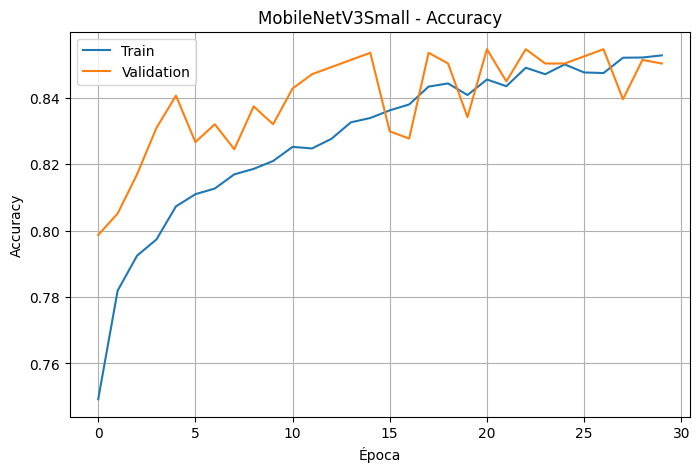

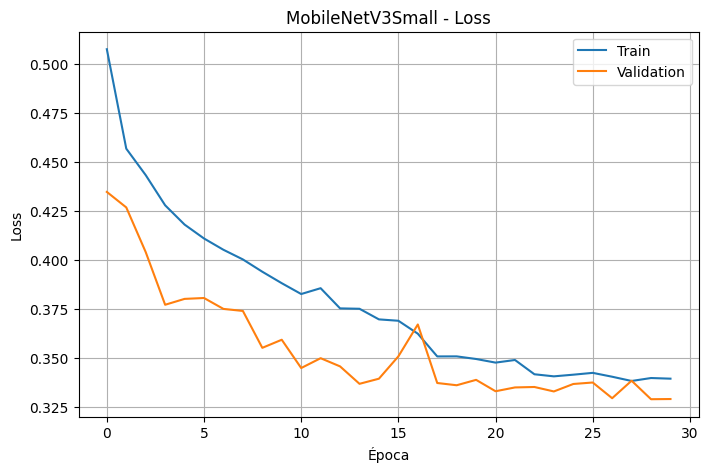

In [11]:
def graficar_historial(history, titulo='MobileNetV3Small'):
    # Crea una nueva figura (lienzo) donde se dibujará el gráfico
    plt.figure(figsize=(8,5))
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Validation')
    plt.xlabel('Época')
    plt.ylabel('Accuracy')
    # Agrega un título al gráfico o imagen mostrada
    plt.title(f'{titulo} - Accuracy')
    plt.legend()
    plt.grid()
    # Renderiza (dibuja) el gráfico en pantalla
    plt.show()

    plt.figure(figsize=(8,5))
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Validation')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.title(f'{titulo} - Loss')
    plt.legend()
    plt.grid()
    plt.show()

graficar_historial(history)


## 7. Etapa 2 — Fine-tuning
Descongelamos únicamente las últimas capas de MobileNet y usamos un *learning rate* mucho menor.


In [12]:
# Descongela estas capas para permitir el fine-tuning (ajuste fino) sobre nuestros datos
base_model.trainable = True

# Congelar todas excepto las últimas 30 capas
for layer in base_model.layers[:-30]:
    # Congela estas capas: no se van a modificar durante el entrenamiento, para conservar lo que ya aprendieron
    layer.trainable = False

print('Capas totales del backbone:', len(base_model.layers))
print('Capas entrenables:', sum(layer.trainable for layer in base_model.layers))

# Configura el modelo antes de entrenar: qué función de pérdida usar, qué optimizador, y qué métricas medir
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)


Capas totales del backbone: 157
Capas entrenables: 30


In [13]:
callbacks_ft = [
    # Callback que detiene el entrenamiento automáticamente si el modelo deja de mejorar, ahorrando tiempo y evitando sobreajuste
    EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    # Callback que reduce automáticamente la tasa de aprendizaje cuando el modelo deja de progresar
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    # Callback que guarda automáticamente la mejor versión del modelo durante el entrenamiento
    ModelCheckpoint(
        'MobileNetV3Small_finetuned_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# Entrena el modelo: le muestra los datos de entrenamiento repetidamente y ajusta sus pesos internos para reducir el error
history_ft = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=callbacks_ft,
    verbose=1
)


Epoch 1/30
529/529 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6034 - auc: 0.7084 - loss: 2.6808 - precision: 0.4936 - recall: 0.8392
Epoch 1: val_loss improved from None to 0.41457, saving model to MobileNetV3Small_finetuned_best.keras

Epoch 1: finished saving model to MobileNetV3Small_finetuned_best.keras
529/529 ━━━━━━━━━━━━━━━━━━━━ 41s 42ms/step - accuracy: 0.6557 - auc: 0.7285 - loss: 1.7579 - precision: 0.5375 - recall: 0.7495 - val_accuracy: 0.7976 - val_auc: 0.9122 - val_loss: 0.4146 - val_precision: 0.8967 - val_recall: 0.6570 - learning_rate: 1.0000e-05
Epoch 2/30
524/529 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7250 - auc: 0.7836 - loss: 0.7932 - precision: 0.6470 - recall: 0.6253
Epoch 2: val_loss improved from 0.41457 to 0.40753, saving model to MobileNetV3Small_finetuned_best.keras

Epoch 2: finished saving model to MobileNetV3Small_finetuned_best.keras
529/529 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7300 - auc: 0.7894 - loss: 0.7302 - precision: 0.6555 

## 8. Evaluación

In [14]:
# Evalúa el modelo ya entrenado sobre un conjunto de datos, devolviendo la pérdida y las métricas configuradas
resultados = model.evaluate(X_val, y_val, verbose=0)

print('Resultados de validación:')
for nombre, valor in zip(model.metrics_names, resultados):
    print(f'{nombre}: {valor:.4f}')


Resultados de validación:
loss: 0.2933
compile_metrics: 0.8708


## 9. Matriz de confusión y reporte de clasificación

30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 149ms/step
              precision    recall  f1-score   support

           0     0.8371    0.9313    0.8817       480
           1     0.9165    0.8062    0.8578       449

    accuracy                         0.8708       929
   macro avg     0.8768    0.8687    0.8697       929
weighted avg     0.8754    0.8708    0.8701       929



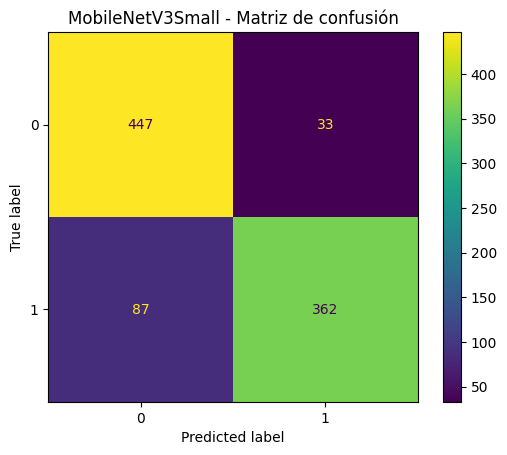

In [15]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Usa el modelo entrenado para generar predicciones sobre nuevas imágenes
y_prob = model.predict(X_val, batch_size=32).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Genera un reporte con Precision, Recall y F1-score para cada clase
print(classification_report(y_val, y_pred, digits=4))

# Calcula la matriz de confusión: compara las predicciones del modelo contra las etiquetas reales
cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
# Agrega un título al gráfico o imagen mostrada
plt.title('MobileNetV3Small - Matriz de confusión')
# Renderiza (dibuja) el gráfico en pantalla
plt.show()


## 10. Guardar modelo final

In [16]:
# Guarda el modelo entrenado (su arquitectura y pesos aprendidos) en un archivo .keras para reutilizarlo sin re-entrenar
model.save('MobileNetV3Small_final.keras')
print('Modelo guardado como MobileNetV3Small_final.keras')


Modelo guardado como MobileNetV3Small_final.keras
